# Heyert Notebook
# Project 2: Text Preprocessing


- Author: [Alex Heyert](https://github.com/ajaneh/)
- Repository: [nlp-02-text-preprocessing](https://github.com/ajaneh/nlp-02-text-preprocessing-custom/)
- Purpose: Tokenize review text and look for trends in word choice across each rating group
- Date: 2026-11

## Section 1. Setup and Imports



In [599]:
# REQ: External packages must be defined in pyproject.toml
# REQ: External packages must be installed in the environment using `uv sync` command
# REQ: External packages used in this notebook must be imported here

from pathlib import Path

import matplotlib.pyplot as plt
from nltk.stem import PorterStemmer
import polars as pl

print("Imports complete.")

Imports complete.


## Section 2. Read the Text Data


In [600]:
NOTEBOOKS_PATH: Path = Path.cwd()
ROOT_PATH: Path = NOTEBOOKS_PATH.parent

DATA_PATH: Path = ROOT_PATH / "data"
NOTEBOOKS_PATH: Path = ROOT_PATH / "notebooks"
SCRIPTS_PATH: Path = ROOT_PATH / "scripts"
IMAGES_PATH: Path = ROOT_PATH / "docs" / "images"

# Choose a text file to analyze.
# Each line is treated as one text record.
input_path: Path = DATA_PATH / "clothing_reviews.csv"

# Read the desired columns in from the CSV file.
reviews: pl.DataFrame = (pl.read_csv(input_path)).select("Rating", "Review Text")
print(reviews.null_count())
reviews = reviews.drop_nulls()

shape: (1, 2)
┌────────┬─────────────┐
│ Rating ┆ Review Text │
│ ---    ┆ ---         │
│ u64    ┆ u64         │
╞════════╪═════════════╡
│ 0      ┆ 845         │
└────────┴─────────────┘


## Section 3. Inspect the Raw Text and Ratings
### Looking at some of the unique text present here
Numbers, such as height and weight, sizes written in abbreviations that may not be recognizable. Missspellings and non-standard empahsis words "sooo"

In [601]:
# Section 3 Python cell

# Review the text records before preprocessing.
# This helps confirm the data loaded correctly and gives a
# sense of the structure of the text.
print("First 50 characters of the first 10 reviews:")
for i, review in enumerate(reviews["Review Text"][:10]):
    print(f"Review {i + 1}: {review[:50]}")

rating_counts: pl.DataFrame = (
    reviews.group_by("Rating").agg(pl.len().alias("reviews")).sort("Rating")
)

print(rating_counts)

First 50 characters of the first 10 reviews:
Review 1: Absolutely wonderful - silky and sexy and comforta
Review 2: Love this dress!  it's sooo pretty.  i happened to
Review 3: I had such high hopes for this dress and really wa
Review 4: I love, love, love this jumpsuit. it's fun, flirty
Review 5: This shirt is very flattering to all due to the ad
Review 6: I love tracy reese dresses, but this one is not fo
Review 7: I aded this in my basket at hte last mintue to see
Review 8: I ordered this in carbon for store pick up, and ha
Review 9: I love this dress. i usually get an xs but it runs
Review 10: I'm 5"5' and 125 lbs. i ordered the s petite to ma
shape: (5, 2)
┌────────┬─────────┐
│ Rating ┆ reviews │
│ ---    ┆ ---     │
│ i64    ┆ u64     │
╞════════╪═════════╡
│ 1      ┆ 821     │
│ 2      ┆ 1549    │
│ 3      ┆ 2823    │
│ 4      ┆ 4908    │
│ 5      ┆ 12540   │
└────────┴─────────┘


## Section 4. Tokenize the Raw Text


In [602]:
# Section 4 Python cell
# Start collecting information about the tokens in each step
def show_counts(stage: str, data: pl.DataFrame) -> int:
    """Used throughout the text preprocessing steps to display token counts.

    Args:
        stage (str): The name of the preprocessing stage.
        data (pl.DataFrame): The DataFrame containing the tokens.

    Returns:
        int: The total number of tokens.
    """
    print(f"{stage}:")
    print(f"  Total tokens: {data.height:,}")
    print(f"  Unique tokens: {data['word'].n_unique():,}")
    return data.height


# Print the number of ALL tokens
raw_words: pl.DataFrame = (
    reviews.select(
        "Rating", pl.col("Review Text").str.extract_all(r"\S+").alias("word")
    )
    .explode("word")
    .drop_nulls("word")
)

count_of_raw_tokens: int = show_counts("Raw tokens", raw_words)

Raw tokens:
  Total tokens: 1,362,913
  Unique tokens: 38,473


## Section 5. Remove Punctuation and Tokenize Again


In [603]:
# Section 6 Python cell

# New punctuation removal strategy, remove all non-alphabetic characters from each word, and dont keep empty strings
clean_words: pl.DataFrame = raw_words.with_columns(
    pl.col("word").str.replace_all(r"[^A-Za-z]", "")
).filter(pl.col("word") != "")

count_of_clean_tokens: int = show_counts("Punctuation removed", clean_words)

Punctuation removed:
  Total tokens: 1,341,410
  Unique tokens: 18,983


## Section 6. Does Capitalization have an association to rating?
It did not, it appears that capitalization didn't play a role in these reviews. No one USED CAPS lock. 

In [604]:
caps_by_rating: pl.DataFrame = (
    clean_words.group_by("Rating")
    .agg(
        pl.len().alias("total_tokens"),
        (
            (pl.col("word").str.len_chars() > 1) &
            (pl.col("word") == pl.col("word").str.to_uppercase())
        ).sum().alias("caps_tokens")
    )
    .with_columns(
        (100 * pl.col("caps_tokens") / pl.col("total_tokens"))
        .round(2)
        .alias("caps_pct")
    )
    .sort("Rating")
)

print(caps_by_rating)

shape: (5, 4)
┌────────┬──────────────┬─────────────┬──────────┐
│ Rating ┆ total_tokens ┆ caps_tokens ┆ caps_pct │
│ ---    ┆ ---          ┆ ---         ┆ ---      │
│ i64    ┆ u64          ┆ u64         ┆ f64      │
╞════════╪══════════════╪═════════════╪══════════╡
│ 1      ┆ 47529        ┆ 0           ┆ 0.0      │
│ 2      ┆ 94750        ┆ 0           ┆ 0.0      │
│ 3      ┆ 178659       ┆ 0           ┆ 0.0      │
│ 4      ┆ 305611       ┆ 0           ┆ 0.0      │
│ 5      ┆ 714861       ┆ 0           ┆ 0.0      │
└────────┴──────────────┴─────────────┴──────────┘


## Section 7. Remove Stop Words

In [605]:
# Section 7 Python cell

# Stop words are very common words that often add little meaning
# for simple frequency analysis.
STOP_WORDS: set[str] = {
    "a",
    "an",
    "and",
    "are",
    "as",
    "at",
    "be",
    "but",
    "by",
    "for",
    "from",
    "has",
    "have",
    "in",
    "is",
    "it",
    "its",
    "of",
    "on",
    "or",
    "that",
    "the",
    "to",
    "was",
    "were",
    "will",
    "with",
    "this",
}

# Apply LowerCase
lower_words: pl.DataFrame = clean_words.with_columns(pl.col("word").str.to_lowercase())
filtered_words: pl.DataFrame = lower_words.filter(
    ~pl.col("word").is_in(STOP_WORDS) & (pl.col("word").str.len_chars() > 2)
)

count_of_stopped_tokens: int = show_counts("Stop words removed", filtered_words)

Stop words removed:
  Total tokens: 750,927
  Unique tokens: 18,065


## Section 8. Stem words

In [606]:
stemmer: PorterStemmer = PorterStemmer()

stem_lookup: pl.DataFrame = (
    filtered_words.select("word")
    .unique()
    .with_columns(
        pl.col("word").map_elements(stemmer.stem, return_dtype=pl.String).alias("stem")
    )
)

stemmed_words: pl.DataFrame = filtered_words.join(stem_lookup, on="word").select(
    "Rating", pl.col("stem").alias("word")
)

count_of_stemmed_tokens: int = show_counts("Stemming", stemmed_words)

Stemming:
  Total tokens: 750,927
  Unique tokens: 13,757


## Section 8. Before After Each Processing Step Summary Table


In [607]:
# Section 8 Python cell

summary_df: pl.DataFrame = pl.DataFrame(
    {
        "stage": ["Raw", "Punctuation", "Lowercase", "Stop words", "Stemming"],
        "total_tokens": [
            raw_words.height,
            clean_words.height,
            lower_words.height,
            filtered_words.height,
            stemmed_words.height,
        ],
        "unique_tokens": [
            raw_words["word"].n_unique(),
            clean_words["word"].n_unique(),
            lower_words["word"].n_unique(),
            filtered_words["word"].n_unique(),
            stemmed_words["word"].n_unique(),
        ],
    }
)

print(summary_df)

shape: (5, 3)
┌─────────────┬──────────────┬───────────────┐
│ stage       ┆ total_tokens ┆ unique_tokens │
│ ---         ┆ ---          ┆ ---           │
│ str         ┆ i64          ┆ i64           │
╞═════════════╪══════════════╪═══════════════╡
│ Raw         ┆ 1362913      ┆ 38473         │
│ Punctuation ┆ 1341410      ┆ 18983         │
│ Lowercase   ┆ 1341410      ┆ 18332         │
│ Stop words  ┆ 750927       ┆ 18065         │
│ Stemming    ┆ 750927       ┆ 13757         │
└─────────────┴──────────────┴───────────────┘


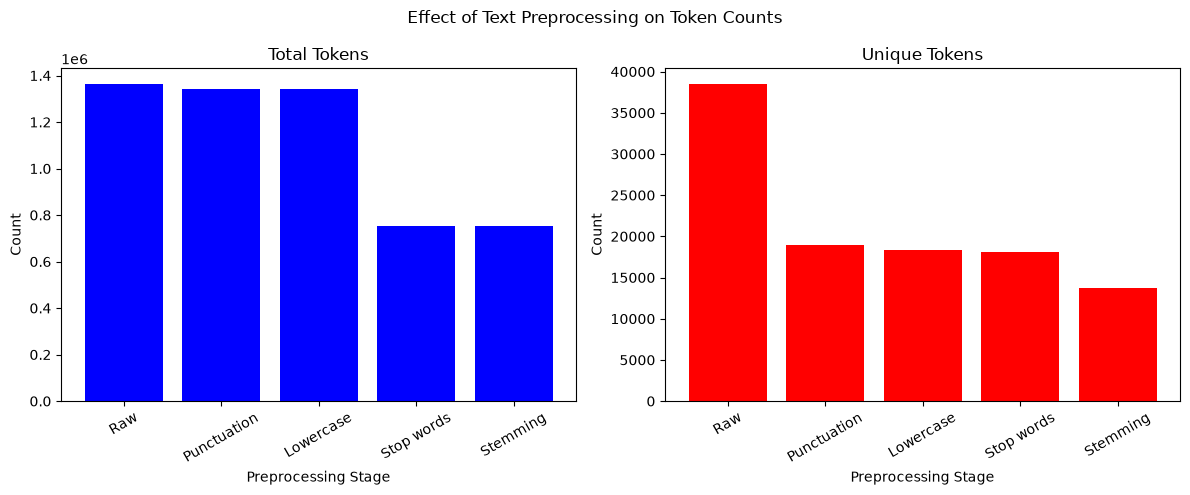

In [608]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(summary_df["stage"], summary_df["total_tokens"], color="blue")
axes[0].set_title("Total Tokens")
axes[0].set_ylabel("Count")

axes[1].bar(summary_df["stage"], summary_df["unique_tokens"], color="red")
axes[1].set_title("Unique Tokens")
axes[1].set_ylabel("Count")

for ax in axes:
    ax.set_xlabel("Preprocessing Stage")
    ax.tick_params(axis="x", labelrotation=30)

fig.suptitle("Effect of Text Preprocessing on Token Counts")
plt.tight_layout()
plt.savefig(IMAGES_PATH / "token_counts_across_preprocessing_stages.png")
plt.show()

## Interpreting tokens across the stages
If we look at total number of tokens, there isnt a meaningful reduction until introducting stop words. However Unique tokens are mostly "corrected" by removing non alpha numeric characters, then stemming reduces it significantly. This is worth looking at closer.

In [609]:
print(
    raw_words.filter(pl.col("word").str.contains(r"[^A-Za-z]"))
    .group_by("word")
    .len()
    .sort("len", descending=True)
    .head(20)
)

shape: (20, 2)
┌──────────────┬──────┐
│ word         ┆ len  │
│ ---          ┆ ---  │
│ str          ┆ u64  │
╞══════════════╪══════╡
│ it's         ┆ 6164 │
│ i'm          ┆ 5082 │
│ it.          ┆ 3122 │
│ -            ┆ 2636 │
│ me.          ┆ 1875 │
│ …            ┆ …    │
│ &            ┆ 899  │
│ can't        ┆ 886  │
│ on.          ┆ 854  │
│ comfortable. ┆ 823  │
│ well.        ┆ 823  │
└──────────────┴──────┘


Looking at what punctuation removes, the first few should maybe be added as stop words, but it appears many people used the same word at the end of a sentence. I.E. "comfortable." the total count still remained high but the values used to describe how clothes fit "comfortable" "well" were unique. 

In [610]:
print(
    raw_words.group_by(
        pl.col("word").str.replace_all(r"[^A-Za-z]", "").alias("cleaned")
    )
    .agg(
        pl.col("word").n_unique().alias("variants"),
        pl.col("word").unique().alias("originals"),
    )
    .filter(pl.col("variants") > 1)
    .sort("variants", descending=True)
    .head(15)
)

shape: (15, 3)
┌─────────┬──────────┬─────────────────────────────────┐
│ cleaned ┆ variants ┆ originals                       │
│ ---     ┆ ---      ┆ ---                             │
│ str     ┆ u64      ┆ list[str]                       │
╞═════════╪══════════╪═════════════════════════════════╡
│         ┆ 1836     ┆ ["-", "5'8".", … "9/10."]       │
│ lbs     ┆ 210      ┆ ["lbs.", "140lbs", … "115lbs),… │
│ s       ┆ 124      ┆ ["s", "(60's)", … "0's"]        │
│ p       ┆ 77       ┆ ["0p", "10p,", … "6p)."]        │
│ lb      ┆ 72       ┆ ["130lb", "lb)", … "120lb)"]    │
│ …       ┆ …        ┆ …                               │
│ it      ┆ 46       ┆ ["it", "it,", … "it~"]          │
│ in      ┆ 42       ┆ ["in", "in,", … "2in."]         │
│ size    ┆ 36       ┆ ["size)", "size", … "size...10… │
│ petite  ┆ 36       ┆ ["petite.", "petite", … "(peti… │
│ small   ┆ 35       ┆ ["small", "small.", … ""small"… │
└─────────┴──────────┴─────────────────────────────────┘


The explanation for the drop in unique tokens post punctuation is related to the type of data we looked at. Since these are clothing reviews, there were a lot of discussions about weight and order size. Since my method of cleaning also stripped numerical values, we were left with the subjects i.e. weight and size rather than the specifics.

In [611]:
print(clean_words.filter(pl.col("word").str.contains(r"[^A-Za-z]")))
# No words escaped the cleaning process

shape: (0, 2)
┌────────┬──────┐
│ Rating ┆ word │
│ ---    ┆ ---  │
│ i64    ┆ str  │
╞════════╪══════╡
└────────┴──────┘


# Look at token frequency and see if there are any patterns connected to the rating

In [612]:
# Calculate word frequency for each rating
word_freq: pl.DataFrame = filtered_words.group_by("Rating", "word").len(name="count")

print(word_freq.sort("count", descending=True).head(20))

shape: (20, 3)
┌────────┬────────────┬───────┐
│ Rating ┆ word       ┆ count │
│ ---    ┆ ---        ┆ ---   │
│ i64    ┆ str        ┆ u64   │
╞════════╪════════════╪═══════╡
│ 5      ┆ love       ┆ 6186  │
│ 5      ┆ dress      ┆ 5656  │
│ 5      ┆ size       ┆ 4844  │
│ 5      ┆ not        ┆ 4428  │
│ 5      ┆ very       ┆ 4247  │
│ …      ┆ …          ┆ …     │
│ 5      ┆ color      ┆ 2566  │
│ 5      ┆ flattering ┆ 2305  │
│ 4      ┆ dress      ┆ 2294  │
│ 5      ┆ soft       ┆ 2262  │
│ 5      ┆ small      ┆ 2250  │
└────────┴────────────┴───────┘


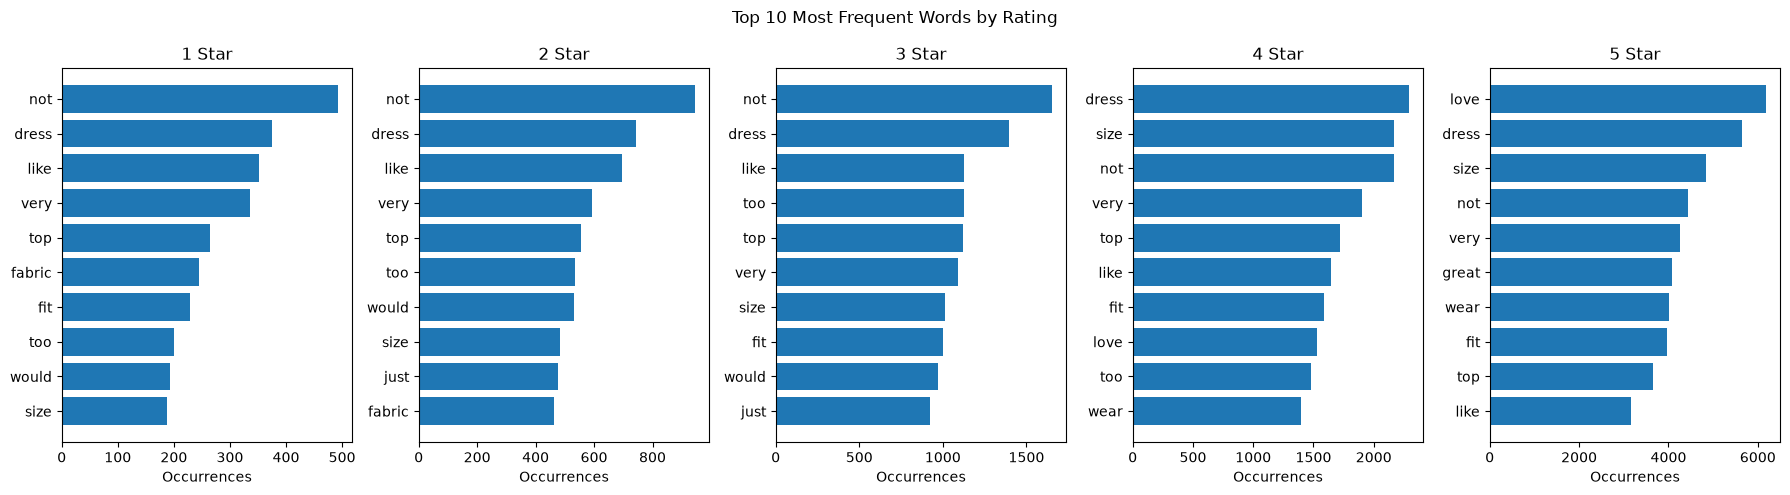

In [613]:
fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for rating, ax in zip(range(1, 6), axes):
    top: pl.DataFrame = (
        word_freq.filter(pl.col("Rating") == rating)
        .sort("count", descending=True)
        .head(10)
        .sort("count")
    )

    ax.barh(top["word"], top["count"])
    ax.set_title(f"{rating} Star")
    ax.set_xlabel("Occurrences")

fig.suptitle("Top 10 Most Frequent Words by Rating")
plt.tight_layout()
plt.savefig(IMAGES_PATH / "top_10_most_frequent_words_by_rating.png")
plt.show()

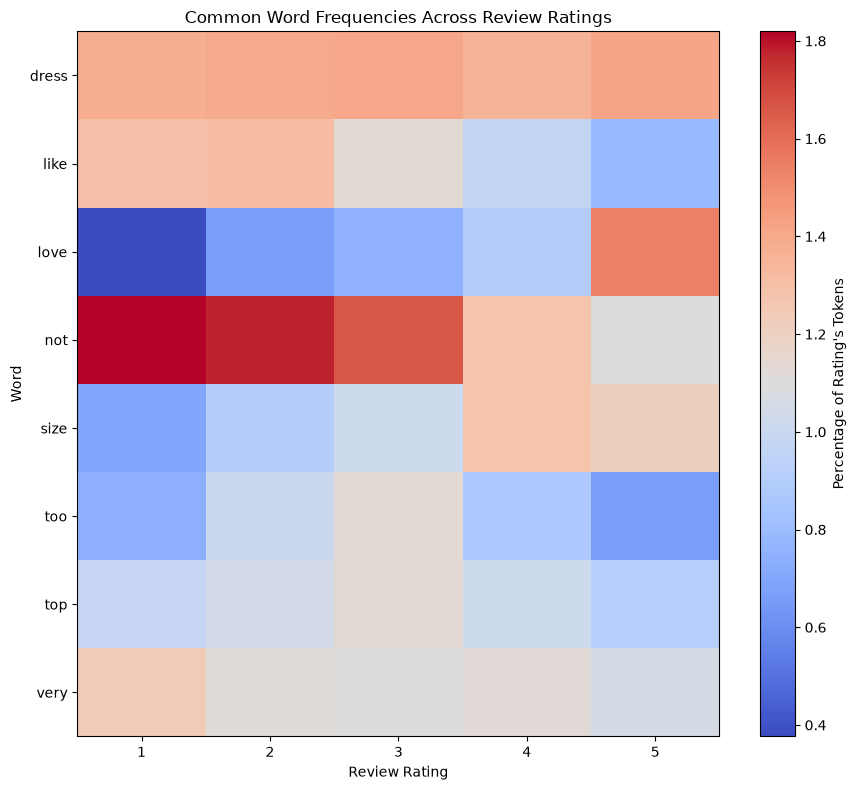

In [614]:
# Bar chart didn't show much, let's try heat map
top_words: list[str] = (
    word_freq.sort(["Rating", "count"], descending=[False, True])
    .group_by("Rating", maintain_order=True)
    .head(5)["word"]
    .unique()
    .to_list()
)

heatmap_df: pl.DataFrame = (
    word_freq.with_columns(
        (100 * pl.col("count") / pl.col("count").sum().over("Rating")).alias("pct")
    )
    .filter(pl.col("word").is_in(top_words))
    .pivot(index="word", on="Rating", values="pct", sort_columns=True)
    .fill_null(0)
    .sort("word")
)

fig, ax = plt.subplots(figsize=(9, 8))

im = ax.imshow(heatmap_df.drop("word").to_numpy(), aspect="auto", cmap="coolwarm")

ax.set_xticks(range(5), heatmap_df.columns[1:])
ax.set_yticks(range(heatmap_df.height), heatmap_df["word"].to_list())

ax.set_xlabel("Review Rating")
ax.set_ylabel("Word")
ax.set_title("Common Word Frequencies Across Review Ratings")

fig.colorbar(im, ax=ax, label="Percentage of Rating's Tokens")
plt.tight_layout()
plt.savefig(IMAGES_PATH / "common_word_frequencies_across_review_ratings.png")
plt.show()

## Word Interpretation
The bar chart didn't reveal much about which words were used across different ratings.
The heatmap shows somethings, the word "love" is seen most in the highest rating and "like" is seen in the lower ratings. "size" appears more and "too" appears less.
The processings effects were the most interesting part of this, further analysis would be needed to determine a meaningful link between the tokens in the review and the rating. 
